
Loading data from: /content/drive/MyDrive/Colab Notebooks/dataset/train
Total images found: 557
Found 557 files belonging to 2 classes.

Loading data from: /content/drive/MyDrive/Colab Notebooks/dataset/test
Total images found: 140
Found 140 files belonging to 2 classes.
Classes: ['cats', 'dogs']


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 179s 5s/step - accuracy: 0.5153 - loss: 0.7307 - val_accuracy: 0.5000 - val_loss: 0.7023
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 23s 657ms/step - accuracy: 0.4632 - loss: 0.6947 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 41s 655ms/step - accuracy: 0.4829 - loss: 0.6934 - val_accuracy: 0.5286 - val_loss: 0.6932
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 728ms/step - accuracy: 0.5512 - loss: 0.6956 - val_accuracy: 0.5000 - val_loss: 0.6934
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 40s 698ms/step - accuracy: 0.5027 - loss: 0.6921 - val_accuracy: 0.5000 - val_loss: 0.6972
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 24s 689ms/step - accuracy: 0.5583 - loss: 0.6941 - val_accuracy: 0.5000 - val_loss: 0.7314
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 42s 734ms/step - accuracy: 0.5189 - loss: 0.6930 - val_accuracy: 0.5000 - val_loss: 0.7018
Epoch 8/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 23s 660ms/step - accuracy: 0.5350 - loss: 0.6854 - val_accura

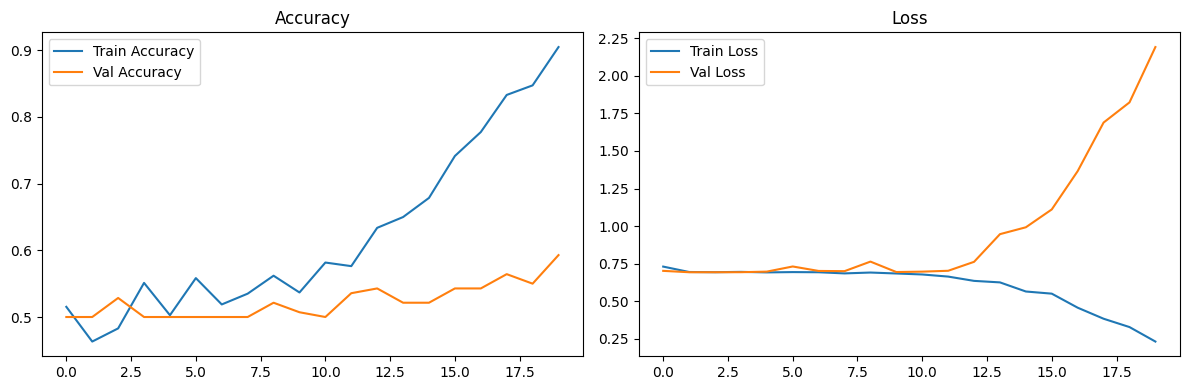

In [1]:
"""
Custom CNN - Binary Image Classification (Robust Version)
Fixes shuffle error + dataset loading issues
"""

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os
import glob

# ------------------------------
# STEP 0: SETTINGS
# ------------------------------
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
EPOCHS = 20

TRAIN_DIR = "/content/drive/MyDrive/Colab Notebooks/dataset/train"
TEST_DIR  = "/content/drive/MyDrive/Colab Notebooks/dataset/test"

# ------------------------------
# STEP 1: SAFE DATA LOADER
# ------------------------------
def load_dataset(data_dir, shuffle=True):
    print(f"\nLoading data from: {data_dir}")

    # Get all image paths (supports jpg + png)
    img_paths = glob.glob(os.path.join(data_dir, "*/*.jpg")) + \
                glob.glob(os.path.join(data_dir, "*/*.png")) + \
                glob.glob(os.path.join(data_dir, "*/*.jpeg"))

    print("Total images found:", len(img_paths))

    if len(img_paths) == 0:
        raise ValueError(f"❌ No images found in {data_dir}. Check path or extensions!")

    # Use built-in loader (best way)
    ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        shuffle=shuffle
    )

    return ds

# Load datasets
train_ds = load_dataset(TRAIN_DIR, shuffle=True)
test_ds  = load_dataset(TEST_DIR, shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)

# ------------------------------
# STEP 2: PREPROCESSING
# ------------------------------
normalization_layer = layers.Rescaling(1./255)

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Apply transformations
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y))

# Performance optimization
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

# ------------------------------
# STEP 3: BUILD CNN MODEL
# ------------------------------
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')  # binary output
])

# ------------------------------
# STEP 4: COMPILE
# ------------------------------
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# ------------------------------
# STEP 5: TRAIN
# ------------------------------
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)

# ------------------------------
# STEP 6: EVALUATE
# ------------------------------
test_loss, test_acc = model.evaluate(test_ds)

print(f"\nTest Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# ------------------------------
# STEP 7: PLOT RESULTS
# ------------------------------
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.savefig("training_curves.png", dpi=120)
print("Saved training_curves.png")

# ------------------------------
# STEP 8: SAVE MODEL
# ------------------------------
model.save("custom_cnn_model.keras")
print("Model saved!")


Loading data from: /content/drive/MyDrive/Colab Notebooks/dataset/train
Total images found: 557
Found 557 files belonging to 2 classes.

Loading data from: /content/drive/MyDrive/Colab Notebooks/dataset/test
Total images found: 140
Found 140 files belonging to 2 classes.
Classes: ['cats', 'dogs']


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 36s 948ms/step - accuracy: 0.5063 - loss: 0.7188 - val_accuracy: 0.5000 - val_loss: 0.6916
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 22s 643ms/step - accuracy: 0.5781 - loss: 0.6802 - val_accuracy: 0.5357 - val_loss: 0.7475
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 41s 646ms/step - accuracy: 0.5583 - loss: 0.6593 - val_accuracy: 0.6071 - val_loss: 0.7101
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 727ms/step - accuracy: 0.6302 - loss: 0.6521 - val_accuracy: 0.6286 - val_loss: 0.7042
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 23s 650ms/step - accuracy: 0.6409 - loss: 0.6305 - val_accuracy: 0.6000 - val_loss: 0.7451
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 42s 668ms/step - accuracy: 0.6876 - loss: 0.6046 - val_accuracy: 0.6286 - val_loss: 0.6809
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 41s 657ms/step - accuracy: 0.7002 - loss: 0.5759 - val_accuracy: 0.6571 - val_loss: 0.7059
Epoch 8/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 718ms/step - accuracy: 0.7271 - loss: 0.5624 - val_accu

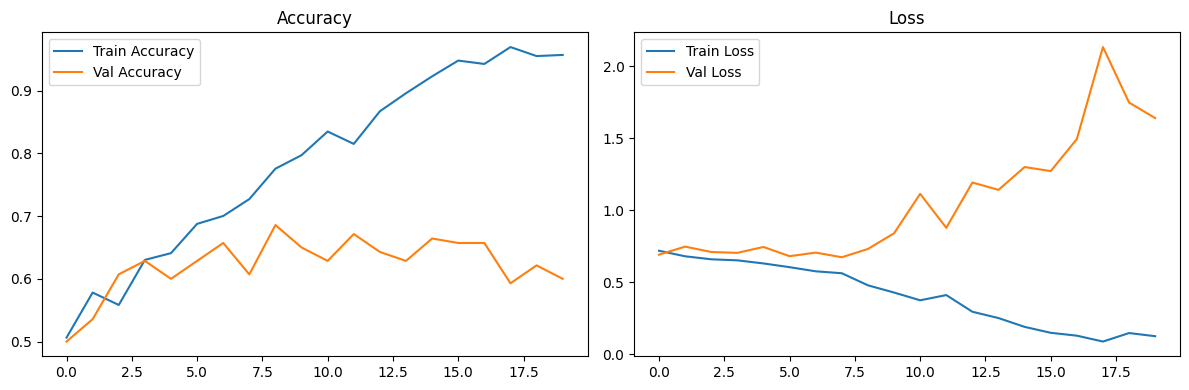

In [2]:
"""
Custom CNN - Binary Image Classification (Robust Version)
Fixes shuffle error + dataset loading issues
"""

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import os
import glob

# ------------------------------
# STEP 0: SETTINGS
# ------------------------------
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
EPOCHS = 20

TRAIN_DIR = "/content/drive/MyDrive/Colab Notebooks/dataset/train"
TEST_DIR  = "/content/drive/MyDrive/Colab Notebooks/dataset/test"

# ------------------------------
# STEP 1: SAFE DATA LOADER
# ------------------------------
def load_dataset(data_dir, shuffle=True):
    print(f"\nLoading data from: {data_dir}")

    # Get all image paths (supports jpg + png)
    img_paths = glob.glob(os.path.join(data_dir, "*/*.jpg")) + \
                glob.glob(os.path.join(data_dir, "*/*.png")) + \
                glob.glob(os.path.join(data_dir, "*/*.jpeg"))

    print("Total images found:", len(img_paths))

    if len(img_paths) == 0:
        raise ValueError(f"❌ No images found in {data_dir}. Check path or extensions!")

    # Use built-in loader (best way)
    ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        shuffle=shuffle
    )

    return ds

# Load datasets
train_ds = load_dataset(TRAIN_DIR, shuffle=True)
test_ds  = load_dataset(TEST_DIR, shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)

# ------------------------------
# STEP 2: PREPROCESSING
# ------------------------------
normalization_layer = layers.Rescaling(1./255)

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Apply transformations
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y))

# Performance optimization
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

# ------------------------------
# STEP 3: BUILD CNN MODEL
# ------------------------------
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')  # binary output
])

# ------------------------------
# STEP 4: COMPILE
# ------------------------------
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# ------------------------------
# STEP 5: TRAIN
# ------------------------------
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)

# ------------------------------
# STEP 6: EVALUATE
# ------------------------------
test_loss, test_acc = model.evaluate(test_ds)

print(f"\nTest Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# ------------------------------
# STEP 7: PLOT RESULTS
# ------------------------------
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.savefig("training_curves.png", dpi=120)
print("Saved training_curves.png")

# ------------------------------
# STEP 8: SAVE MODEL
# ------------------------------
model.save("custom_cnn_model.keras")
print("Model saved!")

# ------------------------------
# STEP 9: PREDICTION ON A NEW IMAGE
# ------------------------------
def predict_image(img_path, model, class_names, img_size=IMG_SIZE, threshold=0.5):
    """
    Loads a single image from disk, runs it through the trained model,
    and prints/shows the predicted class with confidence.
    """
    # Load and preprocess the image the same way training images were processed
    img = tf.keras.utils.load_img(img_path, target_size=img_size)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = img_array / 255.0                     # normalize (must match training)
    img_array = np.expand_dims(img_array, axis=0)      # add batch dimension -> (1, H, W, 3)

    # Run prediction
    prediction = model.predict(img_array, verbose=0)[0][0]  # single sigmoid value between 0 and 1

    # Convert the raw sigmoid output into a class label
    if prediction >= threshold:
        predicted_class = class_names[1]
        confidence = prediction
    else:
        predicted_class = class_names[0]
        confidence = 1 - prediction

    print(f"Image: {img_path}")
    print(f"Predicted class: {predicted_class}  (confidence: {confidence*100:.2f}%)")

    # Show the image with the prediction as the title
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence*100:.1f}%)")
    plt.axis("off")
    plt.show()

    return predicted_class, confidence


# ---- Example usage: predict a single new image ----
# Replace this path with any image you want to test
SAMPLE_IMAGE_PATH = "/content/drive/MyDrive/Colab Notebooks/dataset/test/cats/example.jpg"

if os.path.exists(SAMPLE_IMAGE_PATH):
    predict_image(SAMPLE_IMAGE_PATH, model, class_names)
else:
    print(f"\n(Skipping single-image demo — update SAMPLE_IMAGE_PATH to a real image to test it)")


# ---- Optional: predict on every image in a folder ----
def predict_folder(folder_path, model, class_names, img_size=IMG_SIZE):
    """
    Runs prediction on every image inside a folder and prints a summary table.
    Useful for quickly checking a batch of new/unlabeled images.
    """
    image_paths = glob.glob(os.path.join(folder_path, "*.jpg")) + \
                  glob.glob(os.path.join(folder_path, "*.png")) + \
                  glob.glob(os.path.join(folder_path, "*.jpeg"))

    if len(image_paths) == 0:
        print(f"No images found in {folder_path}")
        return

    print(f"\nPredicting {len(image_paths)} images from: {folder_path}\n")
    for path in image_paths:
        img = tf.keras.utils.load_img(path, target_size=img_size)
        img_array = tf.keras.utils.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        prediction = model.predict(img_array, verbose=0)[0][0]
        predicted_class = class_names[1] if prediction >= 0.5 else class_names[0]
        confidence = prediction if prediction >= 0.5 else 1 - prediction

        print(f"{os.path.basename(path):30s} -> {predicted_class:10s} ({confidence*100:.1f}%)")


# Example: uncomment to predict every image in a folder
# predict_folder("/content/drive/MyDrive/Colab Notebooks/dataset/new_images", model, class_names)